In [1]:
# ============================================================
# HED-XAI-SC: Hybrid Efficient Deep Learning for Skin Cancer
# MobileNetV2 multi-scale features + channel attention
#
# Dataset structure:
# BASE_PATH/
#   train/Benign, train/Malignant
#   val/Benign,   val/Malignant
#   test/Benign,  test/Malignant
#
# Install:
# pip install tensorflow numpy pandas matplotlib scikit-learn pillow
#
# Research prototype only; not clinically validated.
# ============================================================

import os
os.environ["PYTHONHASHSEED"] = "42"

import json
import time
import random
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score, auc
)

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, GlobalAveragePooling2D,
    Concatenate, Multiply, BatchNormalization
)
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, CSVLogger
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model


# ============================================================
# 1. CONFIGURATION -- EDIT PATHS IF NECESSARY
# ============================================================

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 10
LEARNING_RATE = 1e-4
FINE_TUNE_LAST_LAYERS = 30
THRESHOLD = 0.50

BASE_PATH = r"D:\Downloads\Data Analysis\master\Phd\dataset Skin"
OUTPUT_DIR = r"D:\Downloads\Data Analysis\master\Phd\HED_XAI_SC_Results"

CLASS_NAMES = ["Benign", "Malignant"]  # 0 = Benign, 1 = Malignant
VALID_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

os.makedirs(OUTPUT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Best.keras")
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Final.keras")
BEST_H5_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Best.h5")
RESULTS_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Final_Metrics.csv")
REPORT_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Classification_Report.csv")
PREDICTIONS_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Test_Predictions.csv")
SPLIT_MANIFEST = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Split_Manifest.csv")
TRAINING_LOG = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Training_Log.csv")
CONFIG_FILE = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Experiment_Config.json")

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 72)
print("HED-XAI-SC: HYBRID MULTI-SCALE ATTENTION MODEL")
print("=" * 72)
print("TensorFlow:", tf.__version__)
print("Dataset:", BASE_PATH)
print("Output:", OUTPUT_DIR)
print("Epochs:", EPOCHS)


# ============================================================
# 2. COLLECT FILES FROM THE EXISTING TRAIN / VAL / TEST FOLDERS
# ============================================================

SPLIT_DIRS = {
    "train": os.path.join(BASE_PATH, "train"),
    "validation": os.path.join(BASE_PATH, "val"),
    "test": os.path.join(BASE_PATH, "test"),
}

def collect_split(split_dir, split_name):
    if not os.path.isdir(split_dir):
        raise FileNotFoundError(f"{split_name} folder not found: {split_dir}")

    rows = []
    for label, class_name in enumerate(CLASS_NAMES):
        class_dir = os.path.join(split_dir, class_name)
        if not os.path.isdir(class_dir):
            raise FileNotFoundError(
                f"Missing class folder: {class_dir}. "
                f"Expected folders: {CLASS_NAMES}"
            )

        for file_path in sorted(Path(class_dir).rglob("*")):
            if file_path.is_file() and file_path.suffix.lower() in VALID_EXTENSIONS:
                rows.append({
                    "image_path": str(file_path),
                    "label": label,
                    "class_name": class_name,
                    "split": split_name,
                })

    result = pd.DataFrame(rows)
    if result.empty:
        raise ValueError(f"No supported images found in {split_dir}")
    if set(result["label"].unique()) != {0, 1}:
        raise ValueError(f"Both classes must contain images in {split_dir}")
    return result


train_df = collect_split(SPLIT_DIRS["train"], "train")
val_df = collect_split(SPLIT_DIRS["validation"], "validation")
test_df = collect_split(SPLIT_DIRS["test"], "test")

all_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
original_count = len(all_df)


# ============================================================
# 3. SHA-256 DUPLICATE CHECK
#    - Cross-split duplicates stop execution to prevent leakage.
#    - Same-split duplicates with the same label are removed.
#    - Identical image bytes assigned to different classes stop execution.
# ============================================================

def sha256_file(file_path):
    digest = hashlib.sha256()
    with open(file_path, "rb") as file_obj:
        for chunk in iter(lambda: file_obj.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

print("\nCalculating SHA-256 hashes...")
all_df["sha256"] = all_df["image_path"].apply(sha256_file)

# An identical file must not have conflicting labels.
label_counts = all_df.groupby("sha256")["label"].nunique()
conflicting_hashes = label_counts[label_counts > 1].index
if len(conflicting_hashes):
    examples = all_df[all_df["sha256"].isin(conflicting_hashes)][
        ["image_path", "split", "class_name"]
    ].head(10)
    raise ValueError(
        "Identical image files have been assigned different class labels. "
        "Correct these labels before training.\n" + examples.to_string(index=False)
    )

# Detect exact duplicates occurring in more than one split.
split_counts = all_df.groupby("sha256")["split"].nunique()
cross_split_hashes = split_counts[split_counts > 1].index
if len(cross_split_hashes):
    examples = all_df[all_df["sha256"].isin(cross_split_hashes)][
        ["image_path", "split", "class_name"]
    ].head(15)
    raise ValueError(
        "Exact duplicate images occur across train/validation/test splits. "
        "Resolve this leakage before training.\n" + examples.to_string(index=False)
    )

# Remove repeated copies only within their own split.
all_df = all_df.drop_duplicates(subset=["split", "sha256"], keep="first").copy()
duplicates_removed = original_count - len(all_df)

train_df = all_df[all_df["split"] == "train"].copy().reset_index(drop=True)
val_df = all_df[all_df["split"] == "validation"].copy().reset_index(drop=True)
test_df = all_df[all_df["split"] == "test"].copy().reset_index(drop=True)

for split_name, split_df in [
    ("Train", train_df), ("Validation", val_df), ("Test", test_df)
]:
    if split_df.empty or set(split_df["label"].unique()) != {0, 1}:
        raise ValueError(f"Both classes must remain represented in {split_name}.")
    print(f"\n{split_name}: {len(split_df)} images")
    print(split_df["class_name"].value_counts().to_string())

print(f"\nOriginal image files: {original_count}")
print(f"Same-split exact duplicates removed: {duplicates_removed}")
print(f"Unique images retained: {len(all_df)}")

all_df.to_csv(SPLIT_MANIFEST, index=False)
print("Split manifest saved:", SPLIT_MANIFEST)


# ============================================================
# 4. IMAGE GENERATORS
# ============================================================

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=8,
    width_shift_range=0.04,
    height_shift_range=0.04,
    zoom_range=0.08,
    horizontal_flip=True,
    fill_mode="nearest",
)

evaluation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

def make_generator(dataframe, datagen, shuffle):
    return datagen.flow_from_dataframe(
        dataframe=dataframe,
        x_col="image_path",
        y_col="label",
        target_size=(IMG_SIZE, IMG_SIZE),
        color_mode="rgb",
        class_mode="raw",
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
    )

train_generator = make_generator(train_df, train_datagen, shuffle=True)
val_generator = make_generator(val_df, evaluation_datagen, shuffle=False)
test_generator = make_generator(test_df, evaluation_datagen, shuffle=False)


# ============================================================
# 5. BUILD HED-XAI-SC
# ============================================================

print("\nBuilding HED-XAI-SC model...")

backbone = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)

feature_layer_names = [
    "block_3_expand_relu",
    "block_6_expand_relu",
    "out_relu",
]
feature_outputs = [backbone.get_layer(name).output for name in feature_layer_names]

feature_extractor = Model(
    inputs=backbone.input,
    outputs=feature_outputs,
    name="MobileNetV2_MultiScale_Extractor",
)

# Freeze all backbone layers first, then selectively fine-tune the last layers.
backbone.trainable = True
for layer in backbone.layers:
    layer.trainable = False

for layer in backbone.layers[-FINE_TUNE_LAST_LAYERS:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="skin_lesion_input")

# Keep pretrained BatchNorm layers in inference mode.
multi_scale_maps = feature_extractor(inputs, training=False)

pooled_features = [
    GlobalAveragePooling2D(name=f"global_pool_scale_{i + 1}")(feature_map)
    for i, feature_map in enumerate(multi_scale_maps)
]

fused = Concatenate(name="multi_scale_feature_fusion")(pooled_features)
fused = BatchNormalization(name="fusion_batch_norm")(fused)
fused = Dense(256, activation="relu", name="fusion_projection")(fused)
fused = Dropout(0.35, name="fusion_dropout")(fused)

attention = Dense(32, activation="relu", name="channel_attention_hidden")(fused)
attention = Dense(256, activation="sigmoid", name="channel_attention_weights")(attention)
attended = Multiply(name="channel_attention_refinement")([fused, attention])

x = Dense(128, activation="relu", name="classifier_dense")(attended)
x = Dropout(0.25, name="classifier_dropout")(x)
outputs = Dense(1, activation="sigmoid", name="malignant_probability")(x)

model = Model(inputs=inputs, outputs=outputs, name="HED_XAI_SC")

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

model.summary()


# ============================================================
# 6. SAVE EXPERIMENT CONFIGURATION
# ============================================================

config = {
    "model_name": "HED-XAI-SC",
    "architecture": (
        "MobileNetV2 multi-scale feature extraction, concatenation-based "
        "feature fusion, channel-attention refinement, binary classifier"
    ),
    "input_size": [IMG_SIZE, IMG_SIZE, 3],
    "class_mapping": {"Benign": 0, "Malignant": 1},
    "dataset_split": "Pre-existing train/val/test folders; no new split generated",
    "split_counts_after_duplicate_handling": {
        "train": len(train_df),
        "validation": len(val_df),
        "test": len(test_df),
    },
    "original_image_count": original_count,
    "same_split_exact_duplicates_removed": duplicates_removed,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "fine_tune_last_layers": FINE_TUNE_LAST_LAYERS,
    "threshold": THRESHOLD,
    "seed": SEED,
    "preprocessing": "MobileNetV2 preprocess_input",
}

with open(CONFIG_FILE, "w", encoding="utf-8") as file_obj:
    json.dump(config, file_obj, indent=4)


# ============================================================
# 7. CALLBACKS
# ============================================================

checkpoint = ModelCheckpoint(
    filepath=BEST_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1,
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    mode="min",
    verbose=1,
)

csv_logger = CSVLogger(TRAINING_LOG, append=False)
callbacks = [checkpoint, reduce_lr, csv_logger]


# ============================================================
# 8. TRAINING -- EXACTLY 10 EPOCHS UNLESS INTERRUPTED BY AN ERROR
# ============================================================

print("\nStarting training...")
training_start = time.perf_counter()

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

training_seconds = time.perf_counter() - training_start
actual_epochs = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1

print("\nTraining completed.")
print("Epochs completed:", actual_epochs)
print("Best validation-loss epoch:", best_epoch)
print(f"Training time: {training_seconds:.2f} seconds")
print(f"Training time: {training_seconds / 60:.2f} minutes")

# This is the model after the final completed epoch.
model.save(FINAL_MODEL_PATH)


# ============================================================
# 9. SAVE TRAINING HISTORY AND PLOT
# ============================================================

history_df = pd.DataFrame(history.history)
history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
history_df.to_csv(
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_History.csv"), index=False
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(history.history["auc"], label="Training AUC")
axes[2].plot(history.history["val_auc"], label="Validation AUC")
axes[2].set_title("AUC")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("AUC")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_Training_History.png"),
    dpi=300, bbox_inches="tight"
)
plt.close()


# ============================================================
# 10. LOAD THE BEST VALIDATION CHECKPOINT
# ============================================================

print("\nLoading best checkpoint:", BEST_MODEL_PATH)
best_model = load_model(BEST_MODEL_PATH, compile=False)

# Recompile so evaluate() has defined metrics.
best_model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

# Also save the best checkpoint in HDF5 format for compatibility
# with workflows that expect an .h5 file (e.g., older Grad-CAM scripts).
best_model.save(BEST_H5_PATH)


# ============================================================
# 11. TEST EVALUATION AND INFERENCE TIMING
# ============================================================

print("\nEvaluating the held-out test set...")
test_generator.reset()
test_loss, test_accuracy_keras, test_auc_keras, test_precision_keras, test_recall_keras = (
    best_model.evaluate(test_generator, verbose=1)
)

# Warm-up call, excluded from measured prediction time.
test_generator.reset()
warmup_images, _ = next(test_generator)
_ = best_model.predict(warmup_images[:min(4, len(warmup_images))], verbose=0)

# shuffle=False ensures predictions match test_df row order.
test_generator.reset()
inference_start = time.perf_counter()
y_prob = best_model.predict(test_generator, verbose=1).ravel()
inference_seconds = time.perf_counter() - inference_start

y_true = test_df["label"].to_numpy(dtype=int)

if len(y_true) != len(y_prob):
    raise ValueError(
        f"Prediction count ({len(y_prob)}) does not match "
        f"test labels ({len(y_true)})."
    )

y_pred = (y_prob >= THRESHOLD).astype(int)
test_count = len(y_true)
inference_ms_per_image = (inference_seconds / test_count) * 1000
throughput = test_count / inference_seconds if inference_seconds > 0 else 0.0


# ============================================================
# 12. CLASSIFICATION METRICS
# ============================================================

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
sensitivity = recall_score(y_true, y_pred, zero_division=0)
specificity = tn / (tn + fp) if (tn + fp) else 0.0
npv = tn / (tn + fn) if (tn + fn) else 0.0
f1 = f1_score(y_true, y_pred, zero_division=0)

if len(np.unique(y_true)) == 2:
    roc_auc = roc_auc_score(y_true, y_prob)
    average_precision = average_precision_score(y_true, y_prob)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    pr_precision, pr_recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(pr_recall, pr_precision)
else:
    roc_auc = float("nan")
    average_precision = float("nan")
    pr_auc = float("nan")
    fpr, tpr = np.array([]), np.array([])
    pr_precision, pr_recall = np.array([]), np.array([])

print("\n" + "=" * 72)
print("FINAL TEST RESULTS -- HED-XAI-SC")
print("=" * 72)
print(f"Test loss:                 {test_loss:.4f}")
print(f"Accuracy:                  {accuracy * 100:.2f}%")
print(f"Precision (Malignant):     {precision * 100:.2f}%")
print(f"Sensitivity/Recall:        {sensitivity * 100:.2f}%")
print(f"Specificity:               {specificity * 100:.2f}%")
print(f"Negative predictive value: {npv * 100:.2f}%")
print(f"F1-score:                  {f1:.4f}")
print(f"ROC-AUC:                   {roc_auc:.4f}")
print(f"PR-AUC (trapezoidal):      {pr_auc:.4f}")
print(f"Average precision:         {average_precision:.4f}")
print("\nConfusion matrix (rows=actual, columns=predicted):")
print(cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

report_text = classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
)
print("\nClassification report:")
print(report_text)

report_dict = classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
    output_dict=True,
)
pd.DataFrame(report_dict).transpose().to_csv(REPORT_CSV)


# ============================================================
# 13. SAVE TEST PREDICTIONS
# ============================================================

predictions_df = test_df.copy()
predictions_df["actual_class"] = predictions_df["label"].map({
    0: "Benign", 1: "Malignant"
})
predictions_df["predicted_label"] = y_pred
predictions_df["predicted_class"] = [CLASS_NAMES[int(v)] for v in y_pred]
predictions_df["malignant_probability"] = y_prob
predictions_df["correct_prediction"] = (
    predictions_df["label"].to_numpy() == y_pred
)
predictions_df.to_csv(PREDICTIONS_CSV, index=False)


# ============================================================
# 14. SAVE CONFUSION MATRIX, ROC AND PRECISION-RECALL CURVES
# ============================================================

plt.figure(figsize=(7, 6))
plt.imshow(cm, interpolation="nearest")
plt.title("HED-XAI-SC Confusion Matrix")
plt.colorbar()
ticks = np.arange(len(CLASS_NAMES))
plt.xticks(ticks, CLASS_NAMES, rotation=20)
plt.yticks(ticks, CLASS_NAMES)
cutoff = cm.max() / 2.0
for row in range(cm.shape[0]):
    for col in range(cm.shape[1]):
        plt.text(
            col, row, str(cm[row, col]),
            ha="center", va="center",
            color="white" if cm[row, col] > cutoff else "black",
        )
plt.ylabel("Actual class")
plt.xlabel("Predicted class")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_Confusion_Matrix.png"),
    dpi=300, bbox_inches="tight"
)
plt.close()

if len(fpr) > 0:
    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("HED-XAI-SC ROC Curve")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "HED_XAI_SC_ROC_Curve.png"),
        dpi=300, bbox_inches="tight"
    )
    plt.close()

    plt.figure(figsize=(7, 6))
    plt.plot(pr_recall, pr_precision, label=f"PR-AUC = {pr_auc:.4f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("HED-XAI-SC Precision-Recall Curve")
    plt.legend(loc="lower left")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "HED_XAI_SC_PR_Curve.png"),
        dpi=300, bbox_inches="tight"
    )
    plt.close()


# ============================================================
# 15. MODEL SIZE, PARAMETERS AND FINAL METRICS TABLE
# ============================================================

total_params = best_model.count_params()
trainable_params = int(sum(np.prod(v.shape) for v in best_model.trainable_weights))
non_trainable_params = int(
    sum(np.prod(v.shape) for v in best_model.non_trainable_weights)
)
model_size_mb = os.path.getsize(BEST_MODEL_PATH) / (1024 ** 2)
best_h5_size_mb = os.path.getsize(BEST_H5_PATH) / (1024 ** 2)

results = [
    ("Model", "HED-XAI-SC"),
    ("Architecture", "MobileNetV2 multi-scale feature fusion + channel attention"),
    ("Positive class", "Malignant"),
    ("Negative class", "Benign"),
    ("Input size", f"{IMG_SIZE} x {IMG_SIZE} x 3"),
    ("Requested epochs", EPOCHS),
    ("Epochs completed", actual_epochs),
    ("Best validation-loss epoch", best_epoch),
    ("Batch size", BATCH_SIZE),
    ("Original image files", original_count),
    ("Same-split exact duplicates removed", duplicates_removed),
    ("Unique images retained", len(all_df)),
    ("Training images", len(train_df)),
    ("Validation images", len(val_df)),
    ("Test images", len(test_df)),
    ("Test loss", float(test_loss)),
    ("Test accuracy (%)", accuracy * 100),
    ("Precision (%)", precision * 100),
    ("Sensitivity (%)", sensitivity * 100),
    ("Specificity (%)", specificity * 100),
    ("Negative predictive value (%)", npv * 100),
    ("F1-score", f1),
    ("ROC-AUC", roc_auc),
    ("PR-AUC", pr_auc),
    ("Average precision", average_precision),
    ("True negative", int(tn)),
    ("False positive", int(fp)),
    ("False negative", int(fn)),
    ("True positive", int(tp)),
    ("Total parameters", int(total_params)),
    ("Trainable parameters", trainable_params),
    ("Non-trainable parameters", non_trainable_params),
    ("Best model size Keras format (MB)", model_size_mb),
    ("Best model size H5 format (MB)", best_h5_size_mb),
    ("Training time (seconds)", training_seconds),
    ("Training time (minutes)", training_seconds / 60),
    ("Test prediction time (seconds)", inference_seconds),
    ("Prediction time per image (ms)", inference_ms_per_image),
    ("Prediction throughput (images/second)", throughput),
    ("Decision threshold", THRESHOLD),
    ("Random seed", SEED),
]
results_df = pd.DataFrame(results, columns=["Metric", "Value"])
results_df.to_csv(RESULTS_CSV, index=False)

print("\nFinal metrics table:")
print(results_df.to_string(index=False))

print("\nSaved outputs:")
for output_path in [
    BEST_MODEL_PATH, FINAL_MODEL_PATH, BEST_H5_PATH,
    RESULTS_CSV, REPORT_CSV, PREDICTIONS_CSV,
    SPLIT_MANIFEST, TRAINING_LOG, CONFIG_FILE,
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_History.csv"),
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_Training_History.png"),
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_Confusion_Matrix.png"),
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_ROC_Curve.png"),
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_PR_Curve.png"),
]:
    print(" -", output_path)

print("\nTraining and evaluation script completed successfully.")
print("Use HED_XAI_SC_Best.h5 or HED_XAI_SC_Best.keras for Grad-CAM.")
print("Research note: establish the model's contribution through ablation studies "
      "and independent external validation.")


HED-XAI-SC: HYBRID MULTI-SCALE ATTENTION MODEL
TensorFlow: 2.17.0
Dataset: D:\Downloads\Data Analysis\master\Phd\dataset Skin
Output: D:\Downloads\Data Analysis\master\Phd\HED_XAI_SC_Results
Epochs: 10

Calculating SHA-256 hashes...

Train: 2109 images
class_name
Benign       1152
Malignant     957

Validation: 527 images
class_name
Benign       288
Malignant    239

Test: 660 images
class_name
Benign       360
Malignant    300

Original image files: 3297
Same-split exact duplicates removed: 1
Unique images retained: 3296
Split manifest saved: D:\Downloads\Data Analysis\master\Phd\HED_XAI_SC_Results\HED_XAI_SC_Split_Manifest.csv
Found 2109 validated image filenames.
Found 527 validated image filenames.
Found 660 validated image filenames.

Building HED-XAI-SC model...


Model: "HED_XAI_SC"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ skin_lesion_input   │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MobileNetV2_MultiS… │ [(None, 56, 56,   │  2,257,984 │ skin_lesion_inpu… │
│ (Functional)        │ 144), (None, 28,  │            │                   │
│                     │ 28, 192), (None,  │            │                   │
│                     │ 7, 7, 1280)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_1 │ (None, 144)       │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_2 │ (None, 192)       │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_3 │ (None, 1280)      │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_featur… │ (None, 1616)      │          0 │ global_pool_scal… │
│ (Concatenate)       │                   │            │ global_pool_scal… │
│                     │                   │            │ global_pool_scal… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_batch_norm   │ (None, 1616)      │      6,464 │ multi_scale_feat… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_projection   │ (None, 256)       │    413,952 │ fusion_batch_nor… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dropout      │ (None, 256)       │          0 │ fusion_projectio… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 32)        │      8,224 │ fusion_dropout[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 256)       │      8,448 │ channel_attentio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 256)       │          0 │ fusion_dropout[0… │
│ (Multiply)          │                   │            │ channel_attentio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dense    │ (None, 128)       │     32,896 │ channel_attentio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout  │ (None, 128)       │          0 │ classifier_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ malignant_probabil… │ (None, 1)         │        129 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

Total params: 2,728,097 (10.41 MB)

Trainable params: 1,977,601 (7.54 MB)

Non-trainable params: 750,496 (2.86 MB)


Starting training...
Epoch 1/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 500ms/step - accuracy: 0.7389 - auc: 0.8033 - loss: 0.5205 - precision: 0.7373 - recall: 0.5830
Epoch 1: val_loss improved from None to 0.47801, saving model to D:\Downloads\Data Analysis\master\Phd\HED_XAI_SC_Results\HED_XAI_SC_Best.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 94s 582ms/step - accuracy: 0.7928 - auc: 0.8751 - loss: 0.4444 - precision: 0.7908 - recall: 0.7388 - val_accuracy: 0.7932 - val_auc: 0.8604 - val_loss: 0.4780 - val_precision: 0.8066 - val_recall: 0.7155 - learning_rate: 1.0000e-04
Epoch 2/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 549ms/step - accuracy: 0.8402 - auc: 0.9296 - loss: 0.3424 - precision: 0.8403 - recall: 0.8099
Epoch 2: val_loss improved from 0.47801 to 0.43107, saving model to D:\Downloads\Data Analysis\master\Phd\HED_XAI_SC_Results\HED_XAI_SC_Best.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 79s 599ms/step - accuracy: 0.8483 - auc: 0.9298 - loss: 0.3370 - precision: 0.8342 - recall: 0.8307 - val_accuracy: 0.


Evaluating the held-out test set...
42/42 ━━━━━━━━━━━━━━━━━━━━ 13s 160ms/step - accuracy: 0.8788 - auc: 0.9582 - loss: 0.2674 - precision: 0.8548 - recall: 0.8833
42/42 ━━━━━━━━━━━━━━━━━━━━ 12s 219ms/step

FINAL TEST RESULTS -- HED-XAI-SC
Test loss:                 0.2674
Accuracy:                  87.88%
Precision (Malignant):     85.48%
Sensitivity/Recall:        88.33%
Specificity:               87.50%
Negative predictive value: 90.00%
F1-score:                  0.8689
ROC-AUC:                   0.9595
PR-AUC (trapezoidal):      0.9546
Average precision:         0.9547

Confusion matrix (rows=actual, columns=predicted):
[[315  45]
 [ 35 265]]
TN=315, FP=45, FN=35, TP=265

Classification report:
              precision    recall  f1-score   support

      Benign     0.9000    0.8750    0.8873       360
   Malignant     0.8548    0.8833    0.8689       300

    accuracy                         0.8788       660
   macro avg     0.8774    0.8792    0.8781       660
weighted avg     0.8

HED-XAI-SC: HYBRID MULTI-SCALE ATTENTION MODEL
TensorFlow: 2.17.0
Dataset: D:\Downloads\Data Analysis\master\Phd\dataset Skin
Output: D:\Downloads\Data Analysis\master\Phd\HED_XAI_SC_Results
Epochs: 20

Calculating SHA-256 hashes...

Train: 2109 images
class_name
Benign       1152
Malignant     957

Validation: 527 images
class_name
Benign       288
Malignant    239

Test: 660 images
class_name
Benign       360
Malignant    300

Original image files: 3297
Same-split exact duplicates removed: 1
Unique images retained: 3296
Split manifest saved: D:\Downloads\Data Analysis\master\Phd\HED_XAI_SC_Results\HED_XAI_SC_Split_Manifest.csv
Found 2109 validated image filenames.
Found 527 validated image filenames.
Found 660 validated image filenames.

Building HED-XAI-SC model...


Model: "HED_XAI_SC"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ skin_lesion_input   │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MobileNetV2_MultiS… │ [(None, 56, 56,   │  2,257,984 │ skin_lesion_inpu… │
│ (Functional)        │ 144), (None, 28,  │            │                   │
│                     │ 28, 192), (None,  │            │                   │
│                     │ 7, 7, 1280)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_1 │ (None, 144)       │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_2 │ (None, 192)       │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_3 │ (None, 1280)      │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_featur… │ (None, 1616)      │          0 │ global_pool_scal… │
│ (Concatenate)       │                   │            │ global_pool_scal… │
│                     │                   │            │ global_pool_scal… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_batch_norm   │ (None, 1616)      │      6,464 │ multi_scale_feat… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_projection   │ (None, 256)       │    413,952 │ fusion_batch_nor… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dropout      │ (None, 256)       │          0 │ fusion_projectio… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 32)        │      8,224 │ fusion_dropout[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 256)       │      8,448 │ channel_attentio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 256)       │          0 │ fusion_dropout[0… │
│ (Multiply)          │                   │            │ channel_attentio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dense    │ (None, 128)       │     32,896 │ channel_attentio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout  │ (None, 128)       │          0 │ classifier_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ malignant_probabil… │ (None, 1)         │        129 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

Total params: 2,728,097 (10.41 MB)

Trainable params: 1,977,601 (7.54 MB)

Non-trainable params: 750,496 (2.86 MB)


Starting training...
Epoch 1/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 595ms/step - accuracy: 0.7389 - auc: 0.8033 - loss: 0.5205 - precision: 0.7373 - recall: 0.5830
Epoch 1: val_loss improved from None to 0.47801, saving model to D:\Downloads\Data Analysis\master\Phd\HED_XAI_SC_Results\HED_XAI_SC_Best.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 104s 678ms/step - accuracy: 0.7928 - auc: 0.8751 - loss: 0.4444 - precision: 0.7908 - recall: 0.7388 - val_accuracy: 0.7932 - val_auc: 0.8604 - val_loss: 0.4780 - val_precision: 0.8066 - val_recall: 0.7155 - learning_rate: 1.0000e-04
Epoch 2/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 637ms/step - accuracy: 0.8402 - auc: 0.9296 - loss: 0.3424 - precision: 0.8403 - recall: 0.8099
Epoch 2: val_loss improved from 0.47801 to 0.43107, saving model to D:\Downloads\Data Analysis\master\Phd\HED_XAI_SC_Results\HED_XAI_SC_Best.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 91s 691ms/step - accuracy: 0.8483 - auc: 0.9298 - loss: 0.3370 - precision: 0.8342 - recall: 0.8307 - val_accuracy: 0

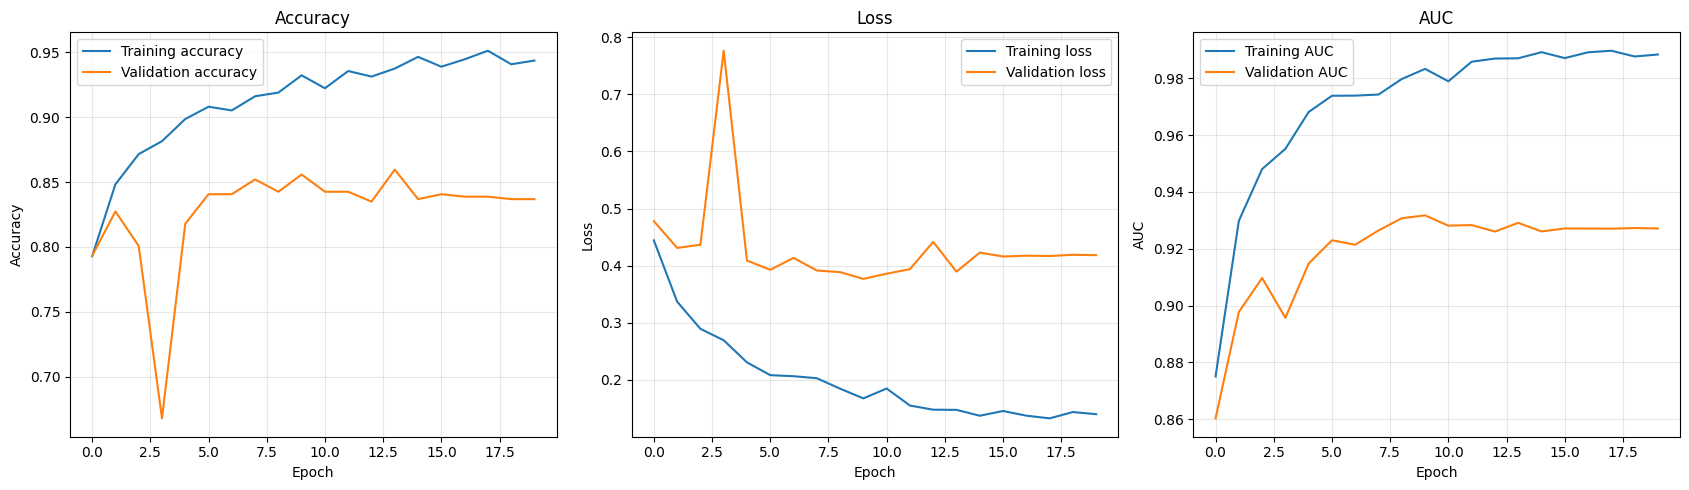


Loading best checkpoint: D:\Downloads\Data Analysis\master\Phd\HED_XAI_SC_Results\HED_XAI_SC_Best.keras



Evaluating the held-out test set...
42/42 ━━━━━━━━━━━━━━━━━━━━ 14s 213ms/step - accuracy: 0.8788 - auc: 0.9582 - loss: 0.2674 - precision: 0.8548 - recall: 0.8833
42/42 ━━━━━━━━━━━━━━━━━━━━ 14s 263ms/step

FINAL TEST RESULTS -- HED-XAI-SC
Test loss:                 0.2674
Accuracy:                  87.88%
Precision (Malignant):     85.48%
Sensitivity/Recall:        88.33%
Specificity:               87.50%
Negative predictive value: 90.00%
F1-score:                  0.8689
ROC-AUC:                   0.9595
PR-AUC (trapezoidal):      0.9546
Average precision:         0.9547

Confusion matrix (rows=actual, columns=predicted):
[[315  45]
 [ 35 265]]
TN=315, FP=45, FN=35, TP=265

Classification report:
              precision    recall  f1-score   support

      Benign     0.9000    0.8750    0.8873       360
   Malignant     0.8548    0.8833    0.8689       300

    accuracy                         0.8788       660
   macro avg     0.8774    0.8792    0.8781       660
weighted avg     0.8

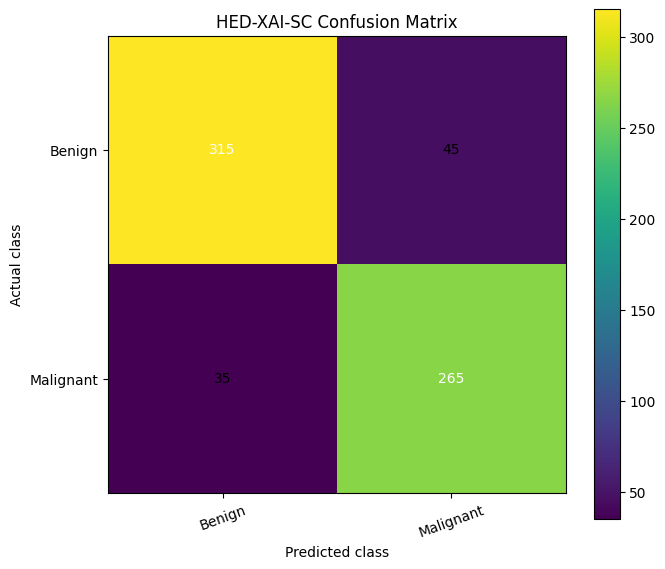

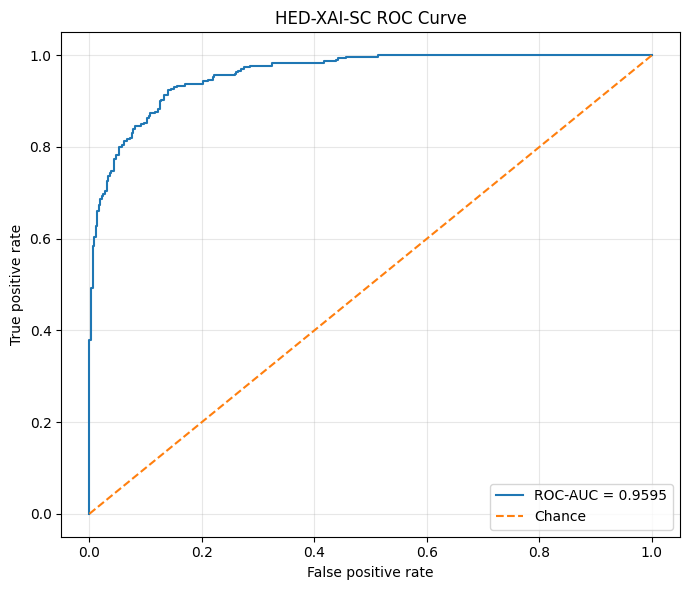

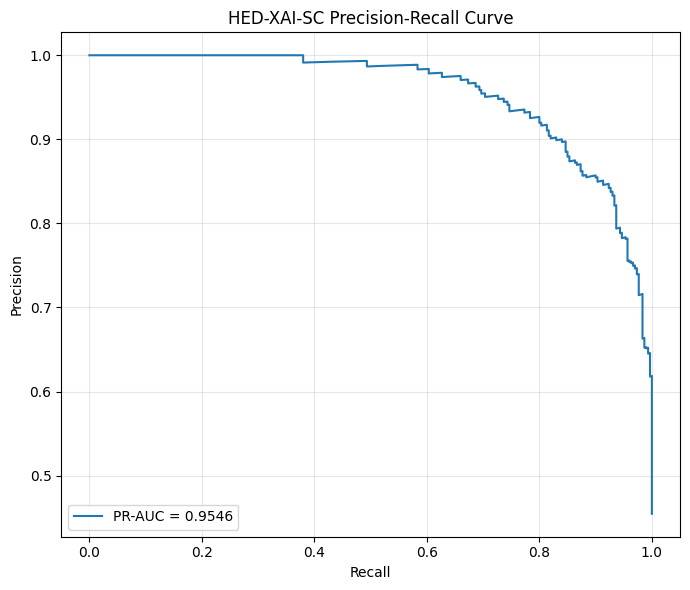


Final metrics table:
                               Metric                                                      Value
                                Model                                                 HED-XAI-SC
                         Architecture MobileNetV2 multi-scale feature fusion + channel attention
                       Positive class                                                  Malignant
                       Negative class                                                     Benign
                           Input size                                              224 x 224 x 3
                     Requested epochs                                                         20
                     Epochs completed                                                         20
           Best validation-loss epoch                                                         10
                           Batch size                                                         16
        

In [2]:
# ============================================================
# HED-XAI-SC: Hybrid Efficient Deep Learning for Skin Cancer
# MobileNetV2 multi-scale features + channel attention
# Training duration: 20 epochs
#
# Dataset structure:
# BASE_PATH/
#   train/Benign, train/Malignant
#   val/Benign,   val/Malignant
#   test/Benign,  test/Malignant
#
# Install:
# pip install tensorflow numpy pandas matplotlib scikit-learn pillow
#
# Research prototype only; not clinically validated.
# ============================================================

import os
os.environ["PYTHONHASHSEED"] = "42"

import json
import time
import random
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score, auc
)

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, GlobalAveragePooling2D,
    Concatenate, Multiply, BatchNormalization
)
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, CSVLogger
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model


# ============================================================
# 1. CONFIGURATION -- EDIT PATHS IF NECESSARY
# ============================================================

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 20
LEARNING_RATE = 1e-4
FINE_TUNE_LAST_LAYERS = 30
THRESHOLD = 0.50

BASE_PATH = r"D:\Downloads\Data Analysis\master\Phd\dataset Skin"
OUTPUT_DIR = r"D:\Downloads\Data Analysis\master\Phd\HED_XAI_SC_Results"

CLASS_NAMES = ["Benign", "Malignant"]  # 0 = Benign, 1 = Malignant
VALID_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

os.makedirs(OUTPUT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Best.keras")
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Final.keras")
BEST_H5_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Best.h5")
RESULTS_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Final_Metrics.csv")
REPORT_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Classification_Report.csv")
PREDICTIONS_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Test_Predictions.csv")
SPLIT_MANIFEST = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Split_Manifest.csv")
TRAINING_LOG = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Training_Log.csv")
CONFIG_FILE = os.path.join(OUTPUT_DIR, "HED_XAI_SC_Experiment_Config.json")

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 72)
print("HED-XAI-SC: HYBRID MULTI-SCALE ATTENTION MODEL")
print("=" * 72)
print("TensorFlow:", tf.__version__)
print("Dataset:", BASE_PATH)
print("Output:", OUTPUT_DIR)
print("Epochs:", EPOCHS)


# ============================================================
# 2. COLLECT FILES FROM THE EXISTING TRAIN / VAL / TEST FOLDERS
# ============================================================

SPLIT_DIRS = {
    "train": os.path.join(BASE_PATH, "train"),
    "validation": os.path.join(BASE_PATH, "val"),
    "test": os.path.join(BASE_PATH, "test"),
}

def collect_split(split_dir, split_name):
    if not os.path.isdir(split_dir):
        raise FileNotFoundError(f"{split_name} folder not found: {split_dir}")

    rows = []
    for label, class_name in enumerate(CLASS_NAMES):
        class_dir = os.path.join(split_dir, class_name)
        if not os.path.isdir(class_dir):
            raise FileNotFoundError(
                f"Missing class folder: {class_dir}. "
                f"Expected folders: {CLASS_NAMES}"
            )

        for file_path in sorted(Path(class_dir).rglob("*")):
            if file_path.is_file() and file_path.suffix.lower() in VALID_EXTENSIONS:
                rows.append({
                    "image_path": str(file_path),
                    "label": label,
                    "class_name": class_name,
                    "split": split_name,
                })

    result = pd.DataFrame(rows)
    if result.empty:
        raise ValueError(f"No supported images found in {split_dir}")
    if set(result["label"].unique()) != {0, 1}:
        raise ValueError(f"Both classes must contain images in {split_dir}")
    return result


train_df = collect_split(SPLIT_DIRS["train"], "train")
val_df = collect_split(SPLIT_DIRS["validation"], "validation")
test_df = collect_split(SPLIT_DIRS["test"], "test")

all_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
original_count = len(all_df)


# ============================================================
# 3. SHA-256 DUPLICATE CHECK
#    - Cross-split duplicates stop execution to prevent leakage.
#    - Same-split duplicates with the same label are removed.
#    - Identical image bytes assigned to different classes stop execution.
# ============================================================

def sha256_file(file_path):
    digest = hashlib.sha256()
    with open(file_path, "rb") as file_obj:
        for chunk in iter(lambda: file_obj.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

print("\nCalculating SHA-256 hashes...")
all_df["sha256"] = all_df["image_path"].apply(sha256_file)

# An identical file must not have conflicting labels.
label_counts = all_df.groupby("sha256")["label"].nunique()
conflicting_hashes = label_counts[label_counts > 1].index
if len(conflicting_hashes):
    examples = all_df[all_df["sha256"].isin(conflicting_hashes)][
        ["image_path", "split", "class_name"]
    ].head(10)
    raise ValueError(
        "Identical image files have been assigned different class labels. "
        "Correct these labels before training.\n" + examples.to_string(index=False)
    )

# Detect exact duplicates occurring in more than one split.
split_counts = all_df.groupby("sha256")["split"].nunique()
cross_split_hashes = split_counts[split_counts > 1].index
if len(cross_split_hashes):
    examples = all_df[all_df["sha256"].isin(cross_split_hashes)][
        ["image_path", "split", "class_name"]
    ].head(15)
    raise ValueError(
        "Exact duplicate images occur across train/validation/test splits. "
        "Resolve this leakage before training.\n" + examples.to_string(index=False)
    )

# Remove repeated copies only within their own split.
all_df = all_df.drop_duplicates(subset=["split", "sha256"], keep="first").copy()
duplicates_removed = original_count - len(all_df)

train_df = all_df[all_df["split"] == "train"].copy().reset_index(drop=True)
val_df = all_df[all_df["split"] == "validation"].copy().reset_index(drop=True)
test_df = all_df[all_df["split"] == "test"].copy().reset_index(drop=True)

for split_name, split_df in [
    ("Train", train_df), ("Validation", val_df), ("Test", test_df)
]:
    if split_df.empty or set(split_df["label"].unique()) != {0, 1}:
        raise ValueError(f"Both classes must remain represented in {split_name}.")
    print(f"\n{split_name}: {len(split_df)} images")
    print(split_df["class_name"].value_counts().to_string())

print(f"\nOriginal image files: {original_count}")
print(f"Same-split exact duplicates removed: {duplicates_removed}")
print(f"Unique images retained: {len(all_df)}")

all_df.to_csv(SPLIT_MANIFEST, index=False)
print("Split manifest saved:", SPLIT_MANIFEST)


# ============================================================
# 4. IMAGE GENERATORS
# ============================================================

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=8,
    width_shift_range=0.04,
    height_shift_range=0.04,
    zoom_range=0.08,
    horizontal_flip=True,
    fill_mode="nearest",
)

evaluation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

def make_generator(dataframe, datagen, shuffle):
    return datagen.flow_from_dataframe(
        dataframe=dataframe,
        x_col="image_path",
        y_col="label",
        target_size=(IMG_SIZE, IMG_SIZE),
        color_mode="rgb",
        class_mode="raw",
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
    )

train_generator = make_generator(train_df, train_datagen, shuffle=True)
val_generator = make_generator(val_df, evaluation_datagen, shuffle=False)
test_generator = make_generator(test_df, evaluation_datagen, shuffle=False)


# ============================================================
# 5. BUILD HED-XAI-SC
# ============================================================

print("\nBuilding HED-XAI-SC model...")

backbone = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)

feature_layer_names = [
    "block_3_expand_relu",
    "block_6_expand_relu",
    "out_relu",
]
feature_outputs = [backbone.get_layer(name).output for name in feature_layer_names]

feature_extractor = Model(
    inputs=backbone.input,
    outputs=feature_outputs,
    name="MobileNetV2_MultiScale_Extractor",
)

# Freeze all backbone layers first, then selectively fine-tune the last layers.
backbone.trainable = True
for layer in backbone.layers:
    layer.trainable = False

for layer in backbone.layers[-FINE_TUNE_LAST_LAYERS:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="skin_lesion_input")

# Keep pretrained BatchNorm layers in inference mode.
multi_scale_maps = feature_extractor(inputs, training=False)

pooled_features = [
    GlobalAveragePooling2D(name=f"global_pool_scale_{i + 1}")(feature_map)
    for i, feature_map in enumerate(multi_scale_maps)
]

fused = Concatenate(name="multi_scale_feature_fusion")(pooled_features)
fused = BatchNormalization(name="fusion_batch_norm")(fused)
fused = Dense(256, activation="relu", name="fusion_projection")(fused)
fused = Dropout(0.35, name="fusion_dropout")(fused)

attention = Dense(32, activation="relu", name="channel_attention_hidden")(fused)
attention = Dense(256, activation="sigmoid", name="channel_attention_weights")(attention)
attended = Multiply(name="channel_attention_refinement")([fused, attention])

x = Dense(128, activation="relu", name="classifier_dense")(attended)
x = Dropout(0.25, name="classifier_dropout")(x)
outputs = Dense(1, activation="sigmoid", name="malignant_probability")(x)

model = Model(inputs=inputs, outputs=outputs, name="HED_XAI_SC")

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

model.summary()


# ============================================================
# 6. SAVE EXPERIMENT CONFIGURATION
# ============================================================

config = {
    "model_name": "HED-XAI-SC",
    "architecture": (
        "MobileNetV2 multi-scale feature extraction, concatenation-based "
        "feature fusion, channel-attention refinement, binary classifier"
    ),
    "input_size": [IMG_SIZE, IMG_SIZE, 3],
    "class_mapping": {"Benign": 0, "Malignant": 1},
    "dataset_split": "Pre-existing train/val/test folders; no new split generated",
    "split_counts_after_duplicate_handling": {
        "train": len(train_df),
        "validation": len(val_df),
        "test": len(test_df),
    },
    "original_image_count": original_count,
    "same_split_exact_duplicates_removed": duplicates_removed,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "fine_tune_last_layers": FINE_TUNE_LAST_LAYERS,
    "threshold": THRESHOLD,
    "seed": SEED,
    "preprocessing": "MobileNetV2 preprocess_input",
}

with open(CONFIG_FILE, "w", encoding="utf-8") as file_obj:
    json.dump(config, file_obj, indent=4)


# ============================================================
# 7. CALLBACKS
# ============================================================

checkpoint = ModelCheckpoint(
    filepath=BEST_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1,
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    mode="min",
    verbose=1,
)

csv_logger = CSVLogger(TRAINING_LOG, append=False)
callbacks = [checkpoint, reduce_lr, csv_logger]


# ============================================================
# 8. TRAINING -- EXACTLY 10 EPOCHS UNLESS INTERRUPTED BY AN ERROR
# ============================================================

print("\nStarting training...")
training_start = time.perf_counter()

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

training_seconds = time.perf_counter() - training_start
actual_epochs = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1

print("\nTraining completed.")
print("Epochs completed:", actual_epochs)
print("Best validation-loss epoch:", best_epoch)
print(f"Training time: {training_seconds:.2f} seconds")
print(f"Training time: {training_seconds / 60:.2f} minutes")
print("Training epochs configured:", EPOCHS)

# This is the model after the final completed epoch.
model.save(FINAL_MODEL_PATH)


# ============================================================
# 9. SAVE TRAINING HISTORY AND PLOT
# ============================================================

history_df = pd.DataFrame(history.history)
history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
history_df.to_csv(
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_History.csv"), index=False
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(history.history["auc"], label="Training AUC")
axes[2].plot(history.history["val_auc"], label="Validation AUC")
axes[2].set_title("AUC")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("AUC")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_Training_History.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()  # Display training accuracy, loss, and AUC after training.
plt.close()


# ============================================================
# 10. LOAD THE BEST VALIDATION CHECKPOINT
# ============================================================

print("\nLoading best checkpoint:", BEST_MODEL_PATH)
best_model = load_model(BEST_MODEL_PATH, compile=False)

# Recompile so evaluate() has defined metrics.
best_model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

# Also save the best checkpoint in HDF5 format for compatibility
# with workflows that expect an .h5 file (e.g., older Grad-CAM scripts).
best_model.save(BEST_H5_PATH)


# ============================================================
# 11. TEST EVALUATION AND INFERENCE TIMING
# ============================================================

print("\nEvaluating the held-out test set...")
test_generator.reset()
test_loss, test_accuracy_keras, test_auc_keras, test_precision_keras, test_recall_keras = (
    best_model.evaluate(test_generator, verbose=1)
)

# Warm-up call, excluded from measured prediction time.
test_generator.reset()
warmup_images, _ = next(test_generator)
_ = best_model.predict(warmup_images[:min(4, len(warmup_images))], verbose=0)

# shuffle=False ensures predictions match test_df row order.
test_generator.reset()
inference_start = time.perf_counter()
y_prob = best_model.predict(test_generator, verbose=1).ravel()
inference_seconds = time.perf_counter() - inference_start

y_true = test_df["label"].to_numpy(dtype=int)

if len(y_true) != len(y_prob):
    raise ValueError(
        f"Prediction count ({len(y_prob)}) does not match "
        f"test labels ({len(y_true)})."
    )

y_pred = (y_prob >= THRESHOLD).astype(int)
test_count = len(y_true)
inference_ms_per_image = (inference_seconds / test_count) * 1000
throughput = test_count / inference_seconds if inference_seconds > 0 else 0.0


# ============================================================
# 12. CLASSIFICATION METRICS
# ============================================================

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
sensitivity = recall_score(y_true, y_pred, zero_division=0)
specificity = tn / (tn + fp) if (tn + fp) else 0.0
npv = tn / (tn + fn) if (tn + fn) else 0.0
f1 = f1_score(y_true, y_pred, zero_division=0)

if len(np.unique(y_true)) == 2:
    roc_auc = roc_auc_score(y_true, y_prob)
    average_precision = average_precision_score(y_true, y_prob)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    pr_precision, pr_recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(pr_recall, pr_precision)
else:
    roc_auc = float("nan")
    average_precision = float("nan")
    pr_auc = float("nan")
    fpr, tpr = np.array([]), np.array([])
    pr_precision, pr_recall = np.array([]), np.array([])

print("\n" + "=" * 72)
print("FINAL TEST RESULTS -- HED-XAI-SC")
print("=" * 72)
print(f"Test loss:                 {test_loss:.4f}")
print(f"Accuracy:                  {accuracy * 100:.2f}%")
print(f"Precision (Malignant):     {precision * 100:.2f}%")
print(f"Sensitivity/Recall:        {sensitivity * 100:.2f}%")
print(f"Specificity:               {specificity * 100:.2f}%")
print(f"Negative predictive value: {npv * 100:.2f}%")
print(f"F1-score:                  {f1:.4f}")
print(f"ROC-AUC:                   {roc_auc:.4f}")
print(f"PR-AUC (trapezoidal):      {pr_auc:.4f}")
print(f"Average precision:         {average_precision:.4f}")
print("\nConfusion matrix (rows=actual, columns=predicted):")
print(cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

report_text = classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
)
print("\nClassification report:")
print(report_text)

report_dict = classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
    output_dict=True,
)
pd.DataFrame(report_dict).transpose().to_csv(REPORT_CSV)


# ============================================================
# 13. SAVE TEST PREDICTIONS
# ============================================================

predictions_df = test_df.copy()
predictions_df["actual_class"] = predictions_df["label"].map({
    0: "Benign", 1: "Malignant"
})
predictions_df["predicted_label"] = y_pred
predictions_df["predicted_class"] = [CLASS_NAMES[int(v)] for v in y_pred]
predictions_df["malignant_probability"] = y_prob
predictions_df["correct_prediction"] = (
    predictions_df["label"].to_numpy() == y_pred
)
predictions_df.to_csv(PREDICTIONS_CSV, index=False)


# ============================================================
# 14. SAVE CONFUSION MATRIX, ROC AND PRECISION-RECALL CURVES
# ============================================================

plt.figure(figsize=(7, 6))
plt.imshow(cm, interpolation="nearest")
plt.title("HED-XAI-SC Confusion Matrix")
plt.colorbar()
ticks = np.arange(len(CLASS_NAMES))
plt.xticks(ticks, CLASS_NAMES, rotation=20)
plt.yticks(ticks, CLASS_NAMES)
cutoff = cm.max() / 2.0
for row in range(cm.shape[0]):
    for col in range(cm.shape[1]):
        plt.text(
            col, row, str(cm[row, col]),
            ha="center", va="center",
            color="white" if cm[row, col] > cutoff else "black",
        )
plt.ylabel("Actual class")
plt.xlabel("Predicted class")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_Confusion_Matrix.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()  # Display confusion matrix in the notebook/output.
plt.close()

if len(fpr) > 0:
    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("HED-XAI-SC ROC Curve")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "HED_XAI_SC_ROC_Curve.png"),
        dpi=300, bbox_inches="tight"
    )
    plt.show()  # Display ROC curve.
    plt.close()

    plt.figure(figsize=(7, 6))
    plt.plot(pr_recall, pr_precision, label=f"PR-AUC = {pr_auc:.4f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("HED-XAI-SC Precision-Recall Curve")
    plt.legend(loc="lower left")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "HED_XAI_SC_PR_Curve.png"),
        dpi=300, bbox_inches="tight"
    )
    plt.show()  # Display precision-recall curve.
    plt.close()


# ============================================================
# 15. MODEL SIZE, PARAMETERS AND FINAL METRICS TABLE
# ============================================================

total_params = best_model.count_params()
trainable_params = int(sum(np.prod(v.shape) for v in best_model.trainable_weights))
non_trainable_params = int(
    sum(np.prod(v.shape) for v in best_model.non_trainable_weights)
)
model_size_mb = os.path.getsize(BEST_MODEL_PATH) / (1024 ** 2)
best_h5_size_mb = os.path.getsize(BEST_H5_PATH) / (1024 ** 2)

results = [
    ("Model", "HED-XAI-SC"),
    ("Architecture", "MobileNetV2 multi-scale feature fusion + channel attention"),
    ("Positive class", "Malignant"),
    ("Negative class", "Benign"),
    ("Input size", f"{IMG_SIZE} x {IMG_SIZE} x 3"),
    ("Requested epochs", EPOCHS),
    ("Epochs completed", actual_epochs),
    ("Best validation-loss epoch", best_epoch),
    ("Batch size", BATCH_SIZE),
    ("Original image files", original_count),
    ("Same-split exact duplicates removed", duplicates_removed),
    ("Unique images retained", len(all_df)),
    ("Training images", len(train_df)),
    ("Validation images", len(val_df)),
    ("Test images", len(test_df)),
    ("Test loss", float(test_loss)),
    ("Test accuracy (%)", accuracy * 100),
    ("Precision (%)", precision * 100),
    ("Sensitivity (%)", sensitivity * 100),
    ("Specificity (%)", specificity * 100),
    ("Negative predictive value (%)", npv * 100),
    ("F1-score", f1),
    ("ROC-AUC", roc_auc),
    ("PR-AUC", pr_auc),
    ("Average precision", average_precision),
    ("True negative", int(tn)),
    ("False positive", int(fp)),
    ("False negative", int(fn)),
    ("True positive", int(tp)),
    ("Total parameters", int(total_params)),
    ("Trainable parameters", trainable_params),
    ("Non-trainable parameters", non_trainable_params),
    ("Best model size Keras format (MB)", model_size_mb),
    ("Best model size H5 format (MB)", best_h5_size_mb),
    ("Training time (seconds)", training_seconds),
    ("Training time (minutes)", training_seconds / 60),
    ("Test prediction time (seconds)", inference_seconds),
    ("Prediction time per image (ms)", inference_ms_per_image),
    ("Prediction throughput (images/second)", throughput),
    ("Decision threshold", THRESHOLD),
    ("Random seed", SEED),
]
results_df = pd.DataFrame(results, columns=["Metric", "Value"])
results_df.to_csv(RESULTS_CSV, index=False)

print("\nFinal metrics table:")
print(results_df.to_string(index=False))

print("\nSaved outputs:")
for output_path in [
    BEST_MODEL_PATH, FINAL_MODEL_PATH, BEST_H5_PATH,
    RESULTS_CSV, REPORT_CSV, PREDICTIONS_CSV,
    SPLIT_MANIFEST, TRAINING_LOG, CONFIG_FILE,
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_History.csv"),
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_Training_History.png"),
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_Confusion_Matrix.png"),
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_ROC_Curve.png"),
    os.path.join(OUTPUT_DIR, "HED_XAI_SC_PR_Curve.png"),
]:
    print(" -", output_path)

print("\nTraining and evaluation script completed successfully.")
print("Use HED_XAI_SC_Best.h5 or HED_XAI_SC_Best.keras for Grad-CAM.")
print("Research note: establish the model's contribution through ablation studies "
      "and independent external validation.")
